# Indian Cricketer Face Identification
Run the cells **one by one** (click ▶ on each), top to bottom.

## Step 1: Install

In [1]:
!pip install facenet-pytorch --no-deps -q
!pip install python-docx -q
print('done')

done


## Step 2: Upload `images.zip`
Zip your `images` folder first (right-click it → Compress to ZIP file), then choose that zip when the upload button appears.

In [2]:
from google.colab import files
import zipfile, os, shutil
shutil.rmtree('data', ignore_errors=True)
up = files.upload()
zipfile.ZipFile(list(up.keys())[0]).extractall('data')

IMG = {'.jpg','.jpeg','.png','.webp','.bmp'}
DATA_DIR = None
for root, dirs, fs in os.walk('data'):
    dirs[:] = [d for d in dirs if not d.startswith(('__MACOSX','.'))]
    players = [d for d in dirs if any(os.path.splitext(f)[1].lower() in IMG
               for f in os.listdir(os.path.join(root, d)))]
    if len(players) >= 2:
        DATA_DIR = root; break
print('Dataset folder:', DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

Saving images.zip to images.zip
Dataset folder: data/images
['bhuvneshwar_kumar', 'dinesh_karthik', 'hardik_pandya', 'jasprit_bumrah', 'k._l._rahul', 'kedar_jadhav', 'kuldeep_yadav', 'mohammed_shami', 'ms_dhoni', 'ravindra_jadeja', 'rohit_sharma', 'shikhar_dhawan', 'vijay_shankar', 'virat_kohli', 'yuzvendra_chahal']


Extract embeddings


In [3]:
# Detect each face ONCE, then create 4 versions (original, flipped, brighter, darker) = augmentation
import numpy as np, torch
from pathlib import Path
from PIL import Image, ImageOps
from facenet_pytorch import MTCNN, InceptionResnetV1

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
mtcnn = MTCNN(image_size=160, margin=20, device=dev, post_process=False)   # raw 0-255 crops
resnet = InceptionResnetV1(pretrained='vggface2').eval().to(dev)

def load(p): return ImageOps.exif_transpose(Image.open(p)).convert('RGB')
def pretty(n):
    special = {'ms_dhoni': 'MS Dhoni', 'k._l._rahul': 'KL Rahul'}
    return special.get(n, ' '.join(n.split('_')).title())

@torch.no_grad()
def embed_batch(raw):
    e = resnet(((raw - 127.5) / 128.0).to(dev)).cpu().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)

def variants(raw):
    return torch.stack([raw, torch.flip(raw, dims=[2]),
                        (raw * 1.3).clamp(0, 255), (raw * 0.7).clamp(0, 255)])

X, y, img_id, is_aug = [], [], [], []
counts, n_imgs = {}, 0
for person in sorted(p for p in Path(DATA_DIR).iterdir() if p.is_dir()):
    total = ok = 0
    for f in person.rglob('*'):
        if f.suffix.lower() not in IMG: continue
        total += 1
        try: face = mtcnn(load(f))
        except Exception: continue
        if face is None: continue
        embs = embed_batch(variants(face))
        for k in range(4):
            X.append(embs[k]); y.append(person.name); img_id.append(n_imgs); is_aug.append(k > 0)
        n_imgs += 1; ok += 1
    counts[person.name] = ok
    print(f'{person.name}: {ok}/{total} usable')

X, y = np.array(X), np.array(y); img_id, is_aug = np.array(img_id), np.array(is_aug)
# drop players with fewer than 5 usable photos
good = [n for n, c in counts.items() if c >= 5]
keep = np.isin(y, good); X, y, img_id, is_aug = X[keep], y[keep], img_id[keep], is_aug[keep]
counts = {n: counts[n] for n in good}
print(f'\n{len(good)} players, {int((~is_aug).sum())} original images, {len(X)} embeddings incl. augmentation')

  0%|          | 0.00/107M [00:00<?, ?B/s]

bhuvneshwar_kumar: 35/37 usable
dinesh_karthik: 31/32 usable
hardik_pandya: 40/40 usable
jasprit_bumrah: 20/21 usable
k._l._rahul: 36/36 usable
kedar_jadhav: 36/37 usable
kuldeep_yadav: 43/45 usable
mohammed_shami: 32/35 usable
ms_dhoni: 43/46 usable
ravindra_jadeja: 49/49 usable
rohit_sharma: 49/50 usable
shikhar_dhawan: 40/40 usable
vijay_shankar: 30/31 usable
virat_kohli: 48/48 usable
yuzvendra_chahal: 29/29 usable

15 players, 561 original images, 2244 embeddings incl. augmentation


SVM (linear)         aug=False  acc=0.888 +/- 0.039
SVM (RBF)            aug=False  acc=0.904 +/- 0.036
Logistic Regression  aug=False  acc=0.891 +/- 0.033
KNN (k=5)            aug=False  acc=0.882 +/- 0.018
Random Forest        aug=False  acc=0.895 +/- 0.027
SVM (linear)         aug=True   acc=0.881 +/- 0.030
SVM (RBF)            aug=True   acc=0.907 +/- 0.038
Logistic Regression  aug=True   acc=0.895 +/- 0.030
KNN (k=5)            aug=True   acc=0.900 +/- 0.027
Random Forest        aug=True   acc=0.907 +/- 0.022

===== COMPARISON TABLE (5-fold cross-validation, %) =====
              Model Augmentation     Accuracy  Macro F1
       SVM (linear)           No 88.8 +/- 3.9      88.4
          SVM (RBF)           No 90.4 +/- 3.6      90.2
Logistic Regression           No 89.1 +/- 3.3      88.5
          KNN (k=5)           No 88.2 +/- 1.8      87.5
      Random Forest           No 89.5 +/- 2.7      89.2
       SVM (linear)          Yes 88.1 +/- 3.0      87.5
          SVM (RBF)          

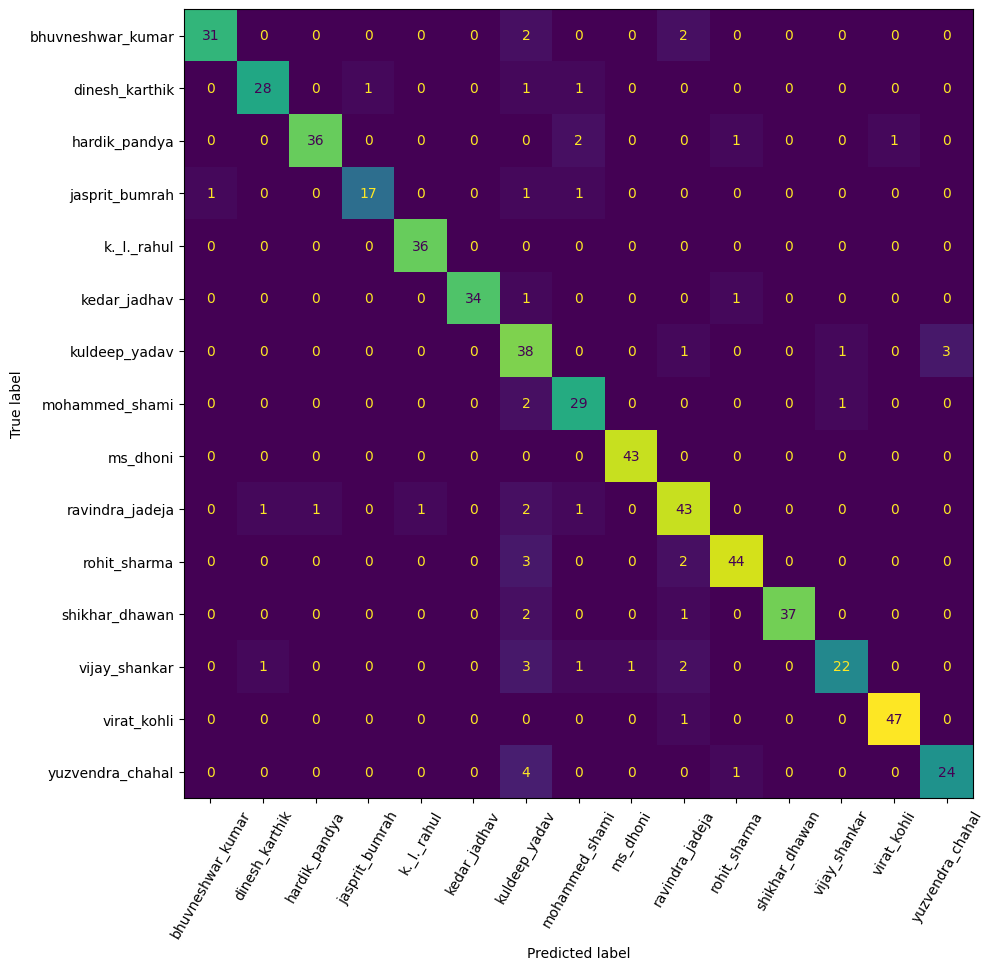

Saved model.joblib   (put scikit-learn==1.6.1 in requirements.txt)


In [4]:
# 5-fold cross-validation + comparison of 5 classifiers, with and without augmentation
import pandas as pd, matplotlib
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

def make_models():
    return {
        'SVM (linear)':        SVC(kernel='linear', C=1, class_weight='balanced'),
        'SVM (RBF)':           SVC(kernel='rbf', C=10, gamma='scale', class_weight='balanced'),
        'Logistic Regression': LogisticRegression(max_iter=3000, C=10),
        'KNN (k=5)':           KNeighborsClassifier(5, weights='distance'),
        'Random Forest':       RandomForestClassifier(300, random_state=42, n_jobs=-1),
    }

# folds are split by ORIGINAL photo, so augmented copies never leak into the test set
orig = np.where(~is_aug)[0]
skf = StratifiedKFold(5, shuffle=True, random_state=42)
folds = []
for tr, te in skf.split(np.zeros(len(orig)), y[orig]):
    tr_ids, te_ids = img_id[orig[tr]], img_id[orig[te]]
    tr_plain = np.where(np.isin(img_id, tr_ids) & ~is_aug)[0]
    tr_aug   = np.where(np.isin(img_id, tr_ids))[0]
    te_idx   = np.where(np.isin(img_id, te_ids) & ~is_aug)[0]
    folds.append((tr_plain, tr_aug, te_idx))

rows, oof = [], {}
for use_aug in (False, True):
    for name in make_models():
        accs, f1s, yt, yp = [], [], [], []
        for tr_plain, tr_aug, te_idx in folds:
            tr = tr_aug if use_aug else tr_plain
            m = make_models()[name].fit(X[tr], y[tr])
            p = m.predict(X[te_idx])
            accs.append(accuracy_score(y[te_idx], p))
            f1s.append(f1_score(y[te_idx], p, average='macro'))
            yt += list(y[te_idx]); yp += list(p)
        oof[(name, use_aug)] = (yt, yp)
        rows.append(dict(Model=name, Augmentation='Yes' if use_aug else 'No',
                         acc_mean=np.mean(accs), acc_std=np.std(accs), f1_mean=np.mean(f1s)))
        print(f'{name:20s} aug={use_aug!s:5s}  acc={np.mean(accs):.3f} +/- {np.std(accs):.3f}')

res = pd.DataFrame(rows)
table = res.assign(Accuracy=lambda d: (d.acc_mean*100).round(1).astype(str) + ' +/- ' + (d.acc_std*100).round(1).astype(str),
                   **{'Macro F1': lambda d: (d.f1_mean*100).round(1)})[['Model','Augmentation','Accuracy','Macro F1']]
print('\n===== COMPARISON TABLE (5-fold cross-validation, %) =====')
print(table.to_string(index=False))

best = res.sort_values('acc_mean', ascending=False).iloc[0]
best_name, best_aug = best['Model'], best['Augmentation'] == 'Yes'
print(f"\nBEST: {best_name}, augmentation={best['Augmentation']}  ->  {best.acc_mean*100:.1f}% +/- {best.acc_std*100:.1f}%")

# out-of-fold predictions of the best setup: every photo is tested exactly once
yt, yp = oof[(best_name, best_aug)]
report_text = classification_report(yt, yp)
report_dict = classification_report(yt, yp, output_dict=True)
print('\n' + report_text)
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(yt, yp, ax=ax, xticks_rotation=60, colorbar=False)
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()

# final model for the app: best classifier trained on ALL data, with probabilities
import joblib, sklearn
final = make_models()[best_name]
if isinstance(final, SVC): final.set_params(probability=True)
final.fit(X if best_aug else X[~is_aug], y if best_aug else y[~is_aug])
joblib.dump(final, 'model.joblib')
print(f'Saved model.joblib   (put scikit-learn=={sklearn.__version__} in requirements.txt)')

## Step 4: Test with a new photo
Upload a photo that was **not** in your training images.

In [5]:
# Auto-generate the project report (Word) from your real results
from docx import Document
from docx.shared import Inches

STUDENT_NAME = 'Ruchitha PR'          # <- edit if needed
APP_URL = 'https://huggingface.co/spaces/ruchithapr/cricket-face-identifier'

doc = Document()
doc.add_heading('Indian Cricket Team Member Face Identification', 0)
doc.add_paragraph(f'Prepared by: {STUDENT_NAME}')

def table_from(header, data):
    t = doc.add_table(rows=1, cols=len(header)); t.style = 'Table Grid'
    for i, h in enumerate(header): t.rows[0].cells[i].text = h
    for r in data:
        cells = t.add_row().cells
        for i, v in enumerate(r): cells[i].text = str(v)

doc.add_heading('1. Problem Statement', 1)
doc.add_paragraph('Develop a computer-vision system that identifies a person from an image using facial '
                  'features, trained on selected Indian cricket team members, and classifies a new image '
                  'into the matching player name.')

doc.add_heading('2. Dataset', 1)
doc.add_paragraph(f'{len(counts)} players, {sum(counts.values())} usable face images '
                  '(images where no face was detected were discarded). Images per player:')
table_from(['Player', 'Usable images'], [(pretty(k), v) for k, v in counts.items()])

doc.add_heading('3. Methodology', 1)
for s in ['Face detection and cropping: MTCNN.',
          'Feature extraction: FaceNet (InceptionResnetV1, pretrained on VGGFace2) producing a 512-dimensional embedding per face.',
          'Data augmentation: horizontal flip, brighter and darker versions of each training face (applied to training data only).',
          'Classification: five classifiers compared (linear SVM, RBF SVM, Logistic Regression, KNN, Random Forest).',
          'Evaluation: stratified 5-fold cross-validation, split by original photo so augmented copies never appear in test data.']:
    doc.add_paragraph(s, style='List Bullet')

doc.add_heading('4. Results', 1)
doc.add_paragraph('Cross-validated accuracy (mean +/- std over 5 folds) and macro F1, in %:')
table_from(['Model', 'Augmentation', 'Accuracy', 'Macro F1'], table.values.tolist())
doc.add_paragraph(f"\nBest configuration: {best_name} with augmentation = {best['Augmentation']}, "
                  f"accuracy {best.acc_mean*100:.1f}% +/- {best.acc_std*100:.1f}%.")
doc.add_heading('Per-player results (out-of-fold predictions)', 2)
classes = [c for c in report_dict if c not in ('accuracy', 'macro avg', 'weighted avg')]
table_from(['Player', 'Precision', 'Recall', 'F1', 'Support'],
           [(pretty(c), f"{report_dict[c]['precision']:.2f}", f"{report_dict[c]['recall']:.2f}",
             f"{report_dict[c]['f1-score']:.2f}", int(report_dict[c]['support'])) for c in classes])
doc.add_heading('Confusion matrix', 2)
doc.add_picture('confusion_matrix.png', width=Inches(5.8))

doc.add_heading('5. Web Application', 1)
doc.add_paragraph(f'A Gradio web app (hosted on Hugging Face Spaces) lets a user upload a photo; it detects every face, '
                  f'names each one, and shows confidence scores, with a threshold below which a face is labelled Unknown. {APP_URL}')

doc.add_heading('6. Limitations', 1)
for s in ['Closed-set recognition: it only knows these players; other people are matched to the closest player unless the confidence threshold marks them Unknown.',
          'Small dataset per player; accuracy may drop for unusual angles, occlusion (caps, sunglasses), low resolution or different lighting.',
          'Photos of the same player from the same event may be near-duplicates, which can make cross-validated accuracy slightly optimistic.',
          'Face recognition systems can show bias and should not be used for surveillance or any high-stakes decision.']:
    doc.add_paragraph(s, style='List Bullet')

doc.add_heading('7. Future Work', 1)
for s in ['Add more players and more varied photos per player.',
          'Try stronger embeddings (e.g. ArcFace) or fine-tune the network.',
          'Add an explicit open-set / "not in the team" detector.',
          'Support video and live camera input.']:
    doc.add_paragraph(s, style='List Bullet')

doc.save('project_report.docx')
print('Saved project_report.docx')

Saved project_report.docx


## Step 5 (optional): Download the trained model

In [6]:
from google.colab import files
files.download('model.joblib')
files.download('project_report.docx')
files.download('confusion_matrix.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>